In [1]:
import os
from pathlib import Path

data_root = Path("/kaggle/input/datasets/hiranomanabu/ransmap-2024-ransomware-behavioral-features/RanSMAP/dataset")
total_size = 0

for root, dirs, files in os.walk(data_root):
    for file in files:
        total_size += os.path.getsize(os.path.join(root, file))

print(f"Total size: {total_size / (1024**3):.2f} GB")

Total size: 160.26 GB


#### Size original :
"111.8 GB (training data (ransomware + benign)" :
- 63.23 GB (celeron-gen6) -- 6 folders and each folder contain saved behaviors (benign(6) and ransomware (6))
- 49.60 GB (i3-gen12) -- same as celeron-gen12 only the cpu changed
#### Size variants :
"9.28 GB (contain 7 conti ransomware -- to test if the model detect the ransomware) 
#### Size mix : 
"10.58 GB (ransomware running at the same time as benign apps (test if the model detect benign and ransomware at the same time))"
#### Size extra : 
"28.57 GB ( additional records)"

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

ransomware = ["Conti", "Darkside", "LockBit", "REvil", "Ryuk", "WannaCry"]
benign = ["AESCrypt", "Firefox", "Idle", "Office", "SDelete", "Zip"]

#### EDA for all ATA-read files

In [3]:

benign_ata_read_paths = []
ransomware_ata_read_paths = []

for folder in data_root.iterdir():
    if not folder.is_dir():
        continue

    for csv_path in folder.rglob("*.csv"):
        if "ata" in csv_path.name.lower() and "read" in csv_path.name.lower():
            for part in csv_path.parts:
                if part in ransomware:
                    ransomware_ata_read_paths.append(csv_path)
                    break
                elif part in benign:
                    benign_ata_read_paths.append(csv_path)
                    break

print("Ransomware ATA-read files:", len(ransomware_ata_read_paths))
print("Benign ATA-read files:", len(benign_ata_read_paths))

Ransomware ATA-read files: 899
Benign ATA-read files: 900


In [4]:
all_ata_read_paths = benign_ata_read_paths + ransomware_ata_read_paths

eda_summary = []

for csv_path in all_ata_read_paths:
    df = pd.read_csv(csv_path, header=None)

    label = "Ransomware" if csv_path in ransomware_ata_read_paths else "Benign"

    eda_summary.append({
        "File": csv_path.name,
        "Class": label,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

eda_summary_df = pd.DataFrame(eda_summary)

display(eda_summary_df.head())

,File,Class,Rows,Columns,Missing Values,Duplicate Rows
0,ata_read.csv,Benign,55000,6,0,1
1,ata_read.csv,Benign,54152,6,0,0
2,ata_read.csv,Benign,13650,6,0,0
3,ata_read.csv,Benign,53421,6,0,1
4,ata_read.csv,Benign,42250,6,0,0


#### Compare benign and ransomware files

In [6]:
display(
    eda_summary_df.groupby("Class")[
        ["Rows", "Columns", "Missing Values", "Duplicate Rows"]
    ].agg(["count", "mean", "min", "max"])
)

Rows                               Columns               \
           count           mean   min      max   count mean min max   
Class                                                                 
Benign       900  285255.471111   676  1566595     900  6.0   6   6   
Ransomware   899  485165.833148  1100  1633102     899  6.0   6   6   

           Missing Values              Duplicate Rows                     
                    count mean min max          count      mean min  max  
Class                                                                     
Benign                900  0.0   0   0            900  0.035556   0    2  
Ransomware            899  0.0   0   0            899  3.604004   0  111

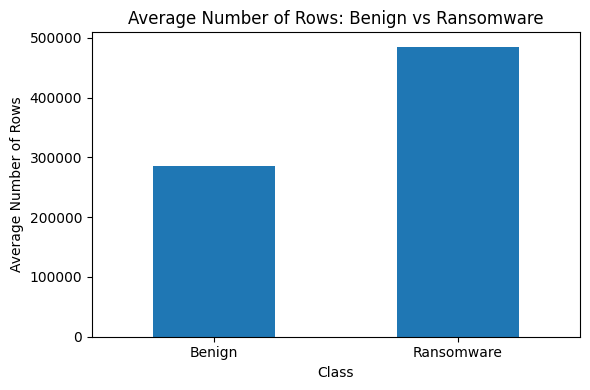

In [7]:
import matplotlib.pyplot as plt

eda_summary_df.groupby("Class")["Rows"].mean().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Average Number of Rows: Benign vs Ransomware")
plt.xlabel("Class")
plt.ylabel("Average Number of Rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### EDA for benign ATA-read files

BENIGN: ata_read.csv

Shape (rows, columns): (102985, 6)

First 5 rows:


,0,1,2,3,4,5
0,1695877075,371420825,22539496,4096,-1,0
1,1695877075,372037014,22539504,4096,-1,0
2,1695877075,372038087,22539512,4096,-1,0
3,1695877075,372038087,22539520,4096,-1,0
4,1695877075,372039161,22539528,4096,-1,0



Data types:
0    int64
1    int64
2    int64
3    int64
4    int64
5    int64
dtype: object

Missing values:
0    0
1    0
2    0
3    0
4    0
5    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,0,1,2,3,4,5
count,1.029850e+05,1.029850e+05,1.029850e+05,102985.000000,102985.0,102985.0
mean,1.695877e+09,4.782900e+08,6.929574e+07,3958.381201,-1.0,0.0
std,5.342623e+01,2.984040e+08,4.083758e+07,582.808676,0.0,0.0
min,1.695877e+09,4.428200e+04,0.000000e+00,512.000000,-1.0,0.0
25%,1.695877e+09,2.091895e+08,4.342570e+07,4096.000000,-1.0,0.0
50%,1.695877e+09,4.754449e+08,6.009345e+07,4096.000000,-1.0,0.0
75%,1.695877e+09,7.431273e+08,9.974800e+07,4096.000000,-1.0,0.0
max,1.695877e+09,9.999328e+08,1.657103e+08,4096.000000,-1.0,0.0


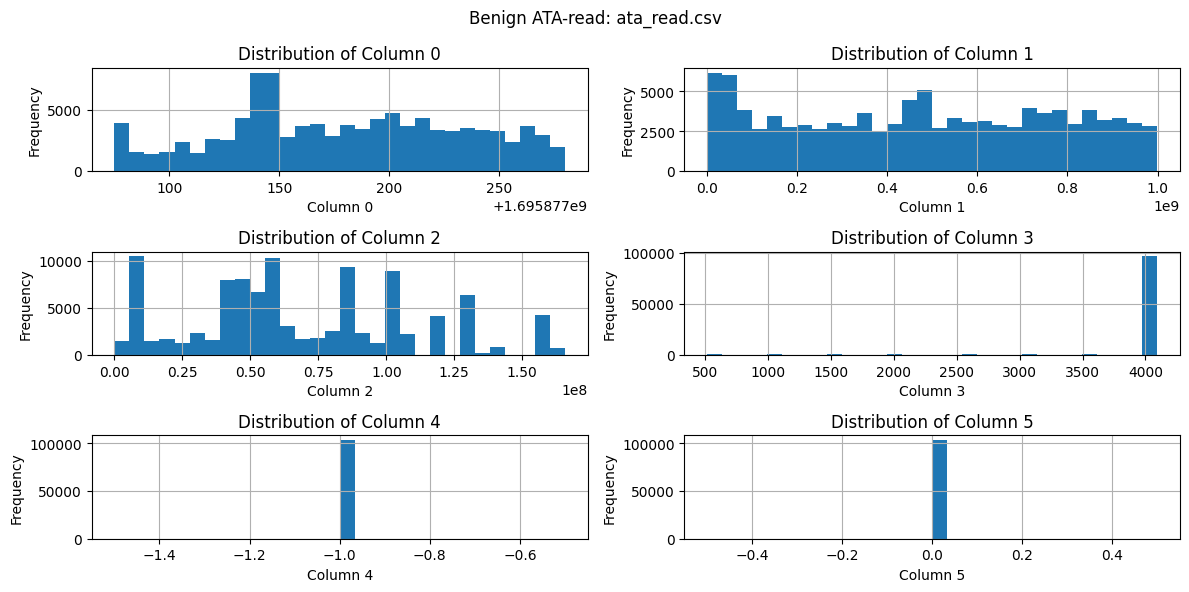

In [8]:
from random import randint

csv_path = benign_ata_read_paths[
    randint(0, len(benign_ata_read_paths) - 1)
]

df = pd.read_csv(csv_path, header=None)

print("BENIGN:", csv_path.name)

print("\nShape (rows, columns):", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

axes = df.hist(figsize=(12, 6), bins=30)

# Ta3tina num taa l colonne li aamlou display
for ax, column in zip(axes.flatten(), df.columns):
    ax.set_title(f"Distribution of Column {column}")
    ax.set_xlabel(f"Column {column}")
    ax.set_ylabel("Frequency")

plt.suptitle(f"Benign ATA-read: {csv_path.name}")
plt.tight_layout()
plt.show()


#### EDA for ransomware ATA-read files

RANSOMWARE: ata_read.csv

Shape (rows, columns): (180028, 6)

First 5 rows:


,0,1,2,3,4,5
0,1673499316,282417907,59139722,4096,-1,0
1,1673499316,282418981,59139730,4096,-1,0
2,1673499316,282418981,59139738,4096,-1,0
3,1673499316,282420054,59139746,4096,-1,0
4,1673499316,282420054,59139754,4096,-1,0



Data types:
0    int64
1    int64
2    int64
3    int64
4    int64
5    int64
dtype: object

Missing values:
0    0
1    0
2    0
3    0
4    0
5    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,0,1,2,3,4,5
count,1.800280e+05,1.800280e+05,1.800280e+05,180028.000000,180028.0,180028.0
mean,1.673499e+09,4.960366e+08,4.420763e+07,3883.857356,-1.0,0.0
std,5.314648e+01,3.023816e+08,3.447834e+07,702.385339,0.0,0.0
min,1.673499e+09,4.840000e+02,0.000000e+00,512.000000,-1.0,0.0
25%,1.673499e+09,2.334756e+08,2.189211e+07,4096.000000,-1.0,0.0
50%,1.673499e+09,5.072933e+08,3.887595e+07,4096.000000,-1.0,0.0
75%,1.673499e+09,7.643869e+08,5.528715e+07,4096.000000,-1.0,0.0
max,1.673500e+09,9.999648e+08,1.657103e+08,4096.000000,-1.0,0.0


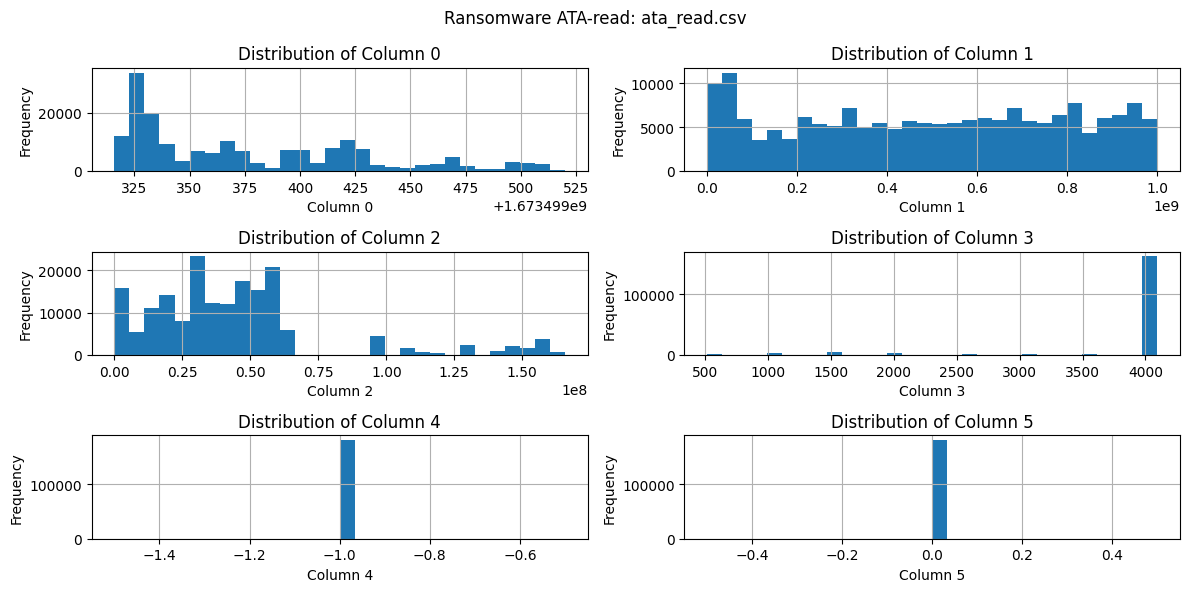

In [9]:
csv_path = ransomware_ata_read_paths[
    randint(0, len(ransomware_ata_read_paths) - 1)
]

df = pd.read_csv(csv_path, header=None)

print("RANSOMWARE:", csv_path.name)

print("\nShape (rows, columns):", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

axes = df.hist(figsize=(12, 6), bins=30)

for ax in axes.flatten():
    column = df.columns[list(axes.flatten()).index(ax)]
    ax.set_title(f"Distribution of Column {column}")
    ax.set_xlabel(f"Column {column}")
    ax.set_ylabel("Frequency")

plt.suptitle(f"Ransomware ATA-read: {csv_path.name}")
plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path

data_types = {
    "ATA-read": lambda n: "ata" in n and "read" in n,
    "ATA-write": lambda n: "ata" in n and "write" in n,
    "Memory-read": lambda n: "mem" in n and "read" in n,
    "Memory-write": lambda n: "mem" in n and "write" in n,
    "Memory-execution": lambda n: (
        "mem" in n and ("exec" in n or "exec" in n)
    )
}

file_groups = {name: {"Benign": [], "Ransomware": []}
               for name in data_types}

for path in data_root.rglob("*.csv"):
    name = path.name.lower()

    for data_type, condition in data_types.items():
        if not condition(name):
            continue

        for part in path.parts:
            if part in benign:
                file_groups[data_type]["Benign"].append(path)
                break
            elif part in ransomware:
                file_groups[data_type]["Ransomware"].append(path)
                break

        break

for data_type, classes in file_groups.items():
    print(
        f"{data_type}: "
        f"Benign={len(classes['Benign'])}, "
        f"Ransomware={len(classes['Ransomware'])}"
    )

ATA-read: Benign=900, Ransomware=899
ATA-write: Benign=900, Ransomware=900
Memory-read: Benign=1800, Ransomware=1800
Memory-write: Benign=900, Ransomware=900
Memory-execution: Benign=900, Ransomware=900
